In [8]:
#import pandas
import pandas as pd
#read data ,movie
movies = pd.read_csv("C:\\Users\\lenovo\\Downloads\\movie_data\movies.csv")

In [9]:
movies.shape      #shape of movie df

(9742, 3)

In [10]:
rating = pd.read_csv("C:\\Users\\lenovo\\Downloads\\movie_data\\ratings.csv")
rating.shape

(100836, 4)

In [11]:
rating.head()       #shape pf rating df

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [12]:
#count userid ,
rating["userId"].value_counts()

userId
414    2698
599    2478
474    2108
448    1864
274    1346
       ... 
442      20
569      20
320      20
576      20
53       20
Name: count, Length: 610, dtype: int64

In [13]:
#maximum no, of rating 
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [14]:
#merge two df
merged_df = pd.merge(rating, movies, on='movieId')


In [15]:
merged_df

,userId,movieId,rating,timestamp,title,genres
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,5,1,4.0,847434962,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
2,7,1,4.5,1106635946,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
3,15,1,2.5,1510577970,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
4,17,1,4.5,1305696483,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
...,...,...,...,...,...,...
100831,610,160341,2.5,1479545749,Bloodmoon (1997),Action|Thriller
100832,610,160527,4.5,1479544998,Sympathy for the Underdog (1971),Action|Crime|Drama
100833,610,160836,3.0,1493844794,Hazard (2005),Action|Drama|Thriller
100834,610,163937,3.5,1493848789,Blair Witch (2016),Horror|Thriller


In [46]:
# Select all correct tags submitted by users to "Matrix, The (1999)" movie
matrix_tags = merged_df.loc[merged_df['title'] == 'Matrix, The (1999)', 'genres'].dropna().unique()
print(matrix_tags)
print(f"The correct tags submitted by users to 'Matrix, The (1999)' are: {', '.join(matrix_tags)}")

['Action|Sci-Fi|Thriller']
The correct tags submitted by users to 'Matrix, The (1999)' are: Action|Sci-Fi|Thriller


In [16]:
# Find the movie with the maximum number of user ratings
max_rate_movie = merged_df['title'].value_counts().idxmax()

In [17]:
print(max_rate_movie)

Forrest Gump (1994)


In [18]:
# Select all correct tags submitted by users to "Matrix, The (1999)"
matrix_tags = merged_df.loc[merged_df['title'] == 'The Matrix,The 1999)', 'genres'].str.split(',').explode().str.strip().unique()
print(matrix_tags)

[]


In [19]:
# Calculate the average user rating for "Terminator 2: Judgment Day (1991)"
average_rating = merged_df.loc[merged_df['title'] == 'Terminator 2: Judgment Day (1991)', 'rating'].mean()
print(average_rating)

3.970982142857143


In [20]:
# Filter ratings for "Fight Club (1999)"
fight_club_ratings = merged_df.loc[merged_df['title'] == 'Fight Club (1999)', 'rating']


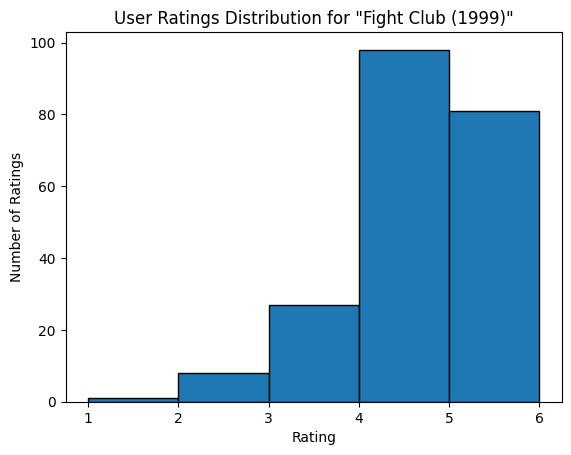

In [21]:
# Plotting the data distribution
import matplotlib.pyplot as plt
plt.hist(fight_club_ratings, bins=[1, 2, 3, 4, 5, 6], edgecolor='black')
plt.title('User Ratings Distribution for "Fight Club (1999)"')
plt.xlabel('Rating')
plt.ylabel('Number of Ratings')
plt.show()

In [22]:
"Fight Club (1999)" in movies["title"]

False

In [23]:
# Calculate average user ratings for each movie
average_ratings = merged_df.groupby('title')['rating'].mean()

# Find the movie with the highest average rating
most_popular_movie = average_ratings.idxmax()

In [24]:
print(most_popular_movie)

'Salem's Lot (2004)


In [25]:
# I. Group the user ratings based on movieId and apply aggregation operations
grouped_ratings = rating.groupby('movieId').agg({'rating': ['count', 'mean']}).reset_index()
grouped_ratings.columns = ['movieId', 'rating_count', 'rating_mean']

# II. Apply inner join on dataframe created from movies.csv and the grouped df from step 1
merged_df = pd.merge(movies, grouped_ratings, on='movieId', how='inner')

# III. Filter only those movies which have more than 50 user ratings
filtered_movies = merged_df[merged_df['rating_count'] > 50]

In [26]:
grouped_ratings.head()

,movieId,rating_count,rating_mean
0,1,215,3.920930
1,2,110,3.431818
2,3,52,3.259615
3,4,7,2.357143
4,5,49,3.071429


In [27]:
merged_df.head()

,movieId,title,genres,rating_count,rating_mean
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,215,3.920930
1,2,Jumanji (1995),Adventure|Children|Fantasy,110,3.431818
2,3,Grumpier Old Men (1995),Comedy|Romance,52,3.259615
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,7,2.357143
4,5,Father of the Bride Part II (1995),Comedy,49,3.071429


In [28]:
#Filter movies with more than 50 user ratings
popular_movies = merged_df[merged_df['rating_count'] > 50]


In [29]:
popular_movies.head()

,movieId,title,genres,rating_count,rating_mean
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,215,3.920930
1,2,Jumanji (1995),Adventure|Children|Fantasy,110,3.431818
2,3,Grumpier Old Men (1995),Comedy|Romance,52,3.259615
5,6,Heat (1995),Action|Crime|Thriller,102,3.946078
6,7,Sabrina (1995),Comedy|Romance,54,3.185185


In [30]:
#Most popular movie based on average user ratings
most_popular_movie = popular_movies.loc[popular_movies['rating_mean'].idxmax(), 'title']


In [31]:
print(most_popular_movie)

Shawshank Redemption, The (1994)


In [32]:
#Top 5 popular movies based on number of user ratings
top_5_popular_movies = popular_movies.sort_values(by='rating_count', ascending=False).head(5)['title'].tolist()
top_5_popular_movies

['Forrest Gump (1994)',
 'Shawshank Redemption, The (1994)',
 'Pulp Fiction (1994)',
 'Silence of the Lambs, The (1991)',
 'Matrix, The (1999)']

In [33]:
#Third most popular Sci-Fi movie based on number of user ratings
sci_fi_movies = popular_movies[popular_movies['genres'] == 'Sci-Fi']


In [34]:
sci_fi_movies

,movieId,title,genres,rating_count,rating_mean


In [35]:
popular_movies["genres"].value_counts()

genres
Comedy                                    24
Comedy|Romance                            21
Drama                                     20
Crime|Drama                               13
Action|Adventure|Sci-Fi                   12
                                          ..
Action|Adventure|Western                   1
Crime|Drama|Sci-Fi|Thriller                1
Horror|Sci-Fi                              1
Action|Adventure|Comedy|Fantasy|Horror     1
Sci-Fi|IMAX                                1
Name: count, Length: 201, dtype: int64

In [36]:
third_most_popular_sci_fi = sci_fi_movies.sort_values(by='rating_count', ascending=False).iloc[2]['title']


IndexError: single positional indexer is out-of-bounds

In [ ]:
#Find the "third most popular" Sci-Fi movie based on the number of user ratings
scifi_movies_df = popular_movies_df[popular_movies_df['genres'].str.contains('Sci-Fi')]
third_most_popular_scifi = scifi_movies_df.sort_values(by='num_ratings', ascending=False).iloc[2]


In [37]:
# web scrapping code


import requests
import numpy as np
from bs4 import BeautifulSoup

def scrapper(imdbId):
    id = str(int(imdbId))
    n_zeroes = 7 - len(id)
    new_id = "0"*n_zeroes + id
    URL = f"https://www.imdb.com/title/tt{new_id}/"
    request_header = {'Content-Type': 'text/html; charset=UTF-8', 
                      'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:109.0) Gecko/20100101 Firefox/119.0', 
                      'Accept-Encoding': 'gzip, deflate, br'}
    response = requests.get(URL, headers=request_header)
    soup = BeautifulSoup(response.text)
    imdb_rating = soup.find('span', attrs={'class' : 'rating'})
    return imdb_rating.text if imdb_rating else np.nan

In [40]:
# Find movieId of the movie with the highest IMDB rating
movies['IMDB_rating'] = movies['movieId'].apply(lambda x: scrapper(x))
highest_rated_movieId = movies.loc[movies_df['IMDB_rating'].idxmax(), 'movieId']

print(f"The movieId of the movie with the highest IMDB rating is: {highest_rated_movieId}")

# Example: Mention the movieId of the "Sci-Fi" movie which has the highest IMDB rating
scifi_movies_df = movies[movies['genre'] == 'Sci-Fi']
highest_rated_scifi_movieId = scifi_movies_df.loc[scifi_movies_df['IMDB_rating'].idxmax(), 'movieId']

print(f"The movieId of the 'Sci-Fi' movie with the highest IMDB rating is: {highest_rated_scifi_movieId}")

KeyboardInterrupt: 